# 03 · Resolution as a function of the triangular-bar size

**Scan setup** (`scripts/scan_bars.sh`, results in `~/runs/scan_bars`):

* full detector, PERPENDICULAR configuration, 270 MeV deuterons, theta uniform in [5°, 17.5°], uniform phi, 500k events per point, same seeds for all points;
* **fixed active area**: 420 mm long bars, 420/b bars per row, 4 rows → 4·420/b SiPM channels; 90 × 90 mm central hole;
* grid: base b ∈ {20, 30, 42, 60, 84} mm × height h ∈ {5, 10, 15, 20, 30} mm (the 2018 prototype is b = 60, h = 20);
* **PHOTOSTAT** smearing calibrated on the test beam (s = 0.180, E_ref = 7 MeV, notebook 02); **CONSTANT** 0.22 for comparison;
* no volume overlaps (Geant4 test on all 25 geometries).

**Metrics** (`sith_reco.py uniform`), each from a Gaussian fit of the residuals in 10 theta intervals, then averaged:

| quantity | residual | what it measures |
|---|---|---|
| σ_r [mm] | r_rec − r_true on the front-layer plane | radial position |
| σ_rφ [mm] | r_true · (φ_rec − φ_true) on the same plane | azimuthal position |
| σ_θ [°] | θ_rec − θ_generated | polar (radial) angle |
| σ_φ [°] | φ_rec − φ_generated, parametrised as A · cot θ | azimuthal angle |

The true position is the intersection of the generated track with the front-layer plane, from the true event vertex (beam spot σ = 0.15 / 0.20 mm). The angles are computed, as in the reconstruction, assuming the vertex at the origin, so they also contain the beam-spot term. The efficiency is the fraction of events with a track reconstructed in both layers.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sithplot as sp
sp.setup()
import sith_reco as sr
R = sp.RUNS / "scan_bars"
df = pd.read_csv(R / "summary.csv")
df["model"] = df.model.str.upper()
BASES, HEIGHTS = sorted(df.base_mm.unique()), sorted(df.height_mm.unique())
ph, co = df[df.model == "PHOTOSTAT"], df[df.model == "CONSTANT"]
proto = ph.query("base_mm == 60 and height_mm == 20").iloc[0]
METRICS = [("sigma_r_mm", "σ_r [mm]", "radial position"),
           ("sigma_rphi_mm", "σ_rφ [mm]", "azimuthal position"),
           ("sigma_theta_deg", "σ_θ [°]", "polar angle"),
           ("sigma_phi_A_deg", "A [°]  (σ_φ = A·cot θ)", "azimuthal angle")]
print(f"{len(df)} points. Prototype (PHOTOSTAT): σ_r = {proto.sigma_r_mm:.3f} mm, σ_rφ = {proto.sigma_rphi_mm:.3f} mm, "
      f"σ_θ = {proto.sigma_theta_deg:.4f}°, σ_φ = {proto.sigma_phi_A_deg:.4f}°·cot θ")

100 points. Prototype (PHOTOSTAT): σ_r = 0.819 mm, σ_rφ = 0.809 mm, σ_θ = 0.0781°, σ_φ = 0.0805°·cot θ


## 1. Results table (PHOTOSTAT)

In [2]:
tab = ph.sort_values(["base_mm", "height_mm"])[["base_mm", "height_mm", "channels", "sigma_r_mm", "sigma_rphi_mm",
                                                 "sigma_theta_deg", "sigma_phi_A_deg", "efficiency"]].copy()
tab["gain vs prototype (σ_θ)"] = proto.sigma_theta_deg / tab.sigma_theta_deg
tab.columns = ["b [mm]", "h [mm]", "channels", "σ_r [mm]", "σ_rφ [mm]", "σ_θ [°]", "A of σ_φ [°]", "efficiency", "gain vs prototype (σ_θ)"]
tab.round({"σ_r [mm]": 3, "σ_rφ [mm]": 3, "σ_θ [°]": 4, "A of σ_φ [°]": 4, "efficiency": 3, "gain vs prototype (σ_θ)": 2}).reset_index(drop=True)

,b [mm],h [mm],channels,σ_r [mm],σ_rφ [mm],σ_θ [°],A of σ_φ [°],efficiency,gain vs prototype (σ_θ)
0,20.0,5.0,84,0.547,0.551,0.0511,0.0536,0.924,1.53
1,20.0,10.0,84,0.390,0.388,0.0388,0.0401,0.952,2.01
2,20.0,15.0,84,0.328,0.322,0.0344,0.0352,0.957,2.27
3,20.0,20.0,84,0.303,0.288,0.0329,0.0329,0.957,2.37
4,20.0,30.0,84,0.303,0.268,0.0341,0.0324,0.949,2.29
5,30.0,5.0,56,0.820,0.822,0.0744,0.0777,0.924,1.05
6,30.0,10.0,56,0.579,0.578,0.0545,0.0569,0.952,1.43
7,30.0,15.0,56,0.476,0.474,0.0467,0.0483,0.958,1.67
8,30.0,20.0,56,0.418,0.416,0.0425,0.0440,0.957,1.84
9,30.0,30.0,56,0.380,0.362,0.0408,0.0406,0.949,1.91


## 2. Theta dependence for the prototype and for a fine-grained geometry

The position resolutions are about constant over the acceptance (with 60 mm bars σ_r has a ±5% modulation, as θ moves the hits with respect to the bar apexes; with 30 mm bars it is smooth); the polar angle follows σ_r / d; the azimuthal angle follows σ_rφ / r = σ_rφ / (d · tan θ), hence the cot θ parametrisation.

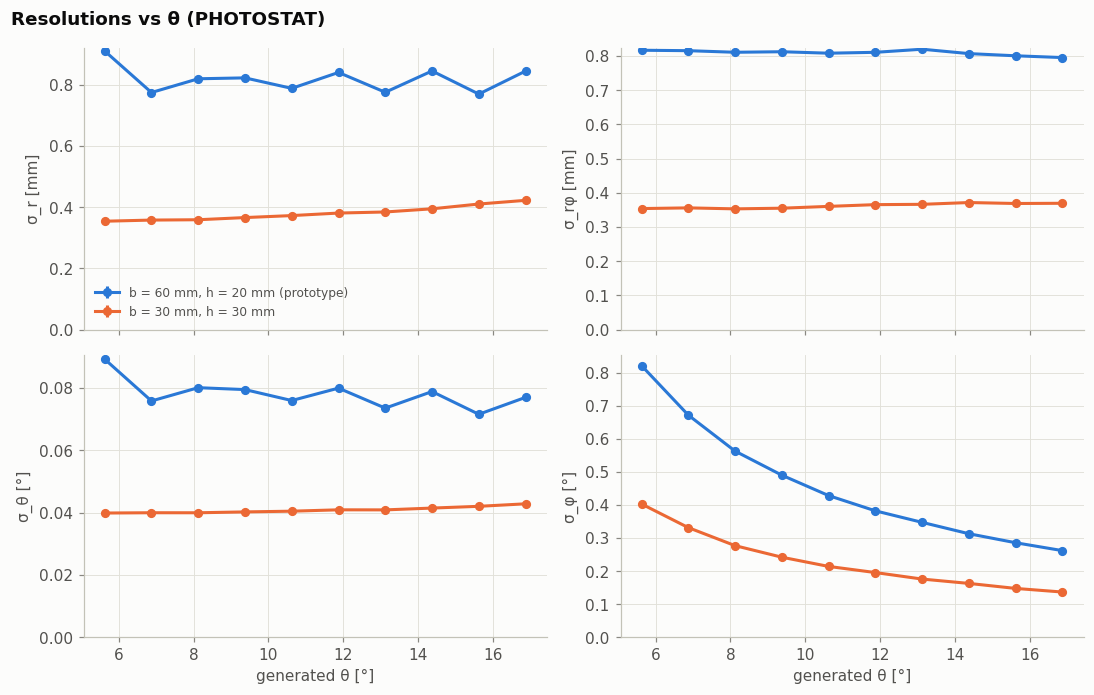

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True)
for i, (b, h) in enumerate(((60, 20), (30, 30))):
    rows = pd.DataFrame(json.load(open(R / "photostat" / f"b{b}_h{h}" / "py_uniform.json"))["per_bin"])
    for ax, (k, lab) in zip(axs.flat, (("sigma_r", "σ_r [mm]"), ("sigma_rphi", "σ_rφ [mm]"),
                                        ("sigma_theta", "σ_θ [°]"), ("sigma_phi", "σ_φ [°]"))):
        ax.errorbar(rows.theta, rows[k], rows[k + "_err"], fmt="o-", color=sp.SERIES[i], ms=5,
                    label=f"b = {b} mm, h = {h} mm" + (" (prototype)" if b == 60 else ""))
        ax.set(ylabel=lab, ylim=(0, None))
for ax in axs[1]: ax.set_xlabel("generated θ [°]")
axs[0, 0].legend(loc="lower left", fontsize=8)
fig.suptitle("Resolutions vs θ (PHOTOSTAT)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 3. The four resolutions as a function of the base

One line per height. At fixed height all four scale roughly linearly with the base: η measures the position over half of the triangle base, so the error in mm grows with b.

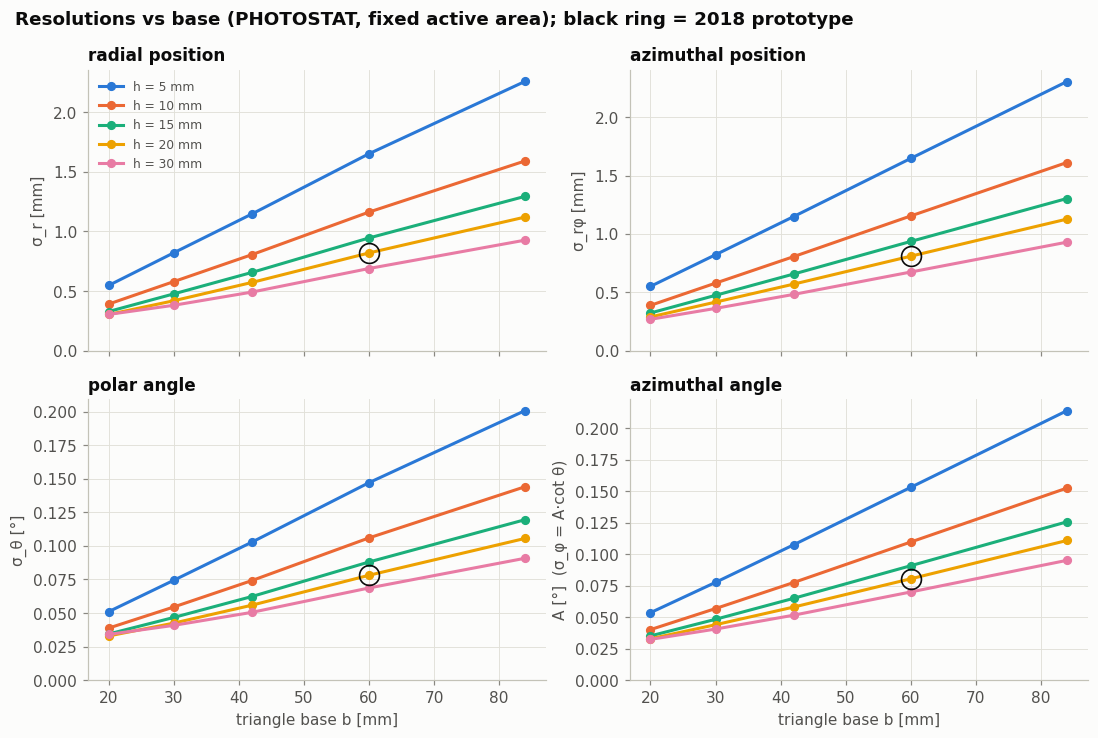

In [4]:
def grid_plot(d, x, series, xlabel, title, series_label, mark_min=False):
    fig, axs = plt.subplots(2, 2, figsize=(10, 6.8), sharex=True)
    keys = sorted(d[series].unique())
    for ax, (col, lab, name) in zip(axs.flat, METRICS):
        for i, s in enumerate(keys):
            g = d[d[series] == s].sort_values(x)
            ax.plot(g[x], g[col], "o-", color=sp.SERIES[i], ms=5, label=series_label(s))
            if mark_min:
                k = g[col].idxmin()
                ax.plot(g.loc[k, x], g.loc[k, col], "o", ms=11, mfc="none", mec=sp.SERIES[i], mew=1.1)
        if x == "base_mm":
            ax.plot(proto.base_mm, proto[col], "o", ms=13, mfc="none", mec=sp.INK, mew=1.1)
        ax.set(title=name, ylabel=lab, ylim=(0, None))
    for ax in axs[1]: ax.set_xlabel(xlabel)
    axs[0, 0].legend(loc="upper left", fontsize=8)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

grid_plot(ph, "base_mm", "height_mm", "triangle base b [mm]",
          "Resolutions vs base (PHOTOSTAT, fixed active area); black ring = 2018 prototype", lambda h: f"h = {h:.0f} mm")

In [5]:
# same for the two smearing models: ratio PHOTOSTAT / CONSTANT for every metric
cmp = ph.merge(co, on=["base_mm", "height_mm"], suffixes=("_ph", "_co"))
out = {}
for col, lab, name in METRICS:
    cmp[name] = cmp[col + "_ph"] / cmp[col + "_co"]
    out[name] = cmp.pivot(index="base_mm", columns="height_mm", values=name).round(3)
print("PHOTOSTAT / CONSTANT (rows: base [mm], columns: height [mm])")
pd.concat(out, axis=0)

PHOTOSTAT / CONSTANT (rows: base [mm], columns: height [mm])


height_mm                    5.0    10.0   15.0   20.0   30.0
                   base_mm                                   
radial position    20.0     1.539  1.279  1.127  1.024  0.892
                   30.0     1.540  1.278  1.126  1.018  0.890
                   42.0     1.541  1.277  1.122  1.015  0.882
                   60.0     1.536  1.271  1.116  1.007  0.866
                   84.0     1.554  1.283  1.126  1.016  0.873
azimuthal position 20.0     1.539  1.273  1.120  1.012  0.883
                   30.0     1.538  1.274  1.117  1.010  0.875
                   42.0     1.540  1.278  1.120  1.010  0.872
                   60.0     1.541  1.276  1.121  1.011  0.868
                   84.0     1.543  1.278  1.121  1.012  0.868
polar angle        20.0     1.441  1.206  1.084  1.008  0.911
                   30.0     1.490  1.238  1.104  1.012  0.903
                   42.0     1.515  1.256  1.111  1.012  0.892
                   60.0     1.523  1.260  1.110  1.006  0.871
                   84.0     1.550  1.277  1.124  1.017  0.875
azimuthal angle    20.0     1.442  1.204  1.080  1.001  0.909
                   30.0     1.492  1.236  1.097  1.007  0.893
                   42.0     1.513  1.257  1.110  1.008  0.883
                   60.0     1.527  1.266  1.114  1.010  0.873
                   84.0     1.536  1.273  1.118  1.013  0.871

With `CONSTANT` the height matters little (the relative energy resolution does not depend on the deposit). With `PHOTOSTAT` low bars lose a lot in all four quantities: at h = 5 mm the deposit is ~4 times smaller than in the prototype and σ_E/E doubles; above 20 mm `PHOTOSTAT` is better than `CONSTANT`.

## 4. The four resolutions as a function of the height

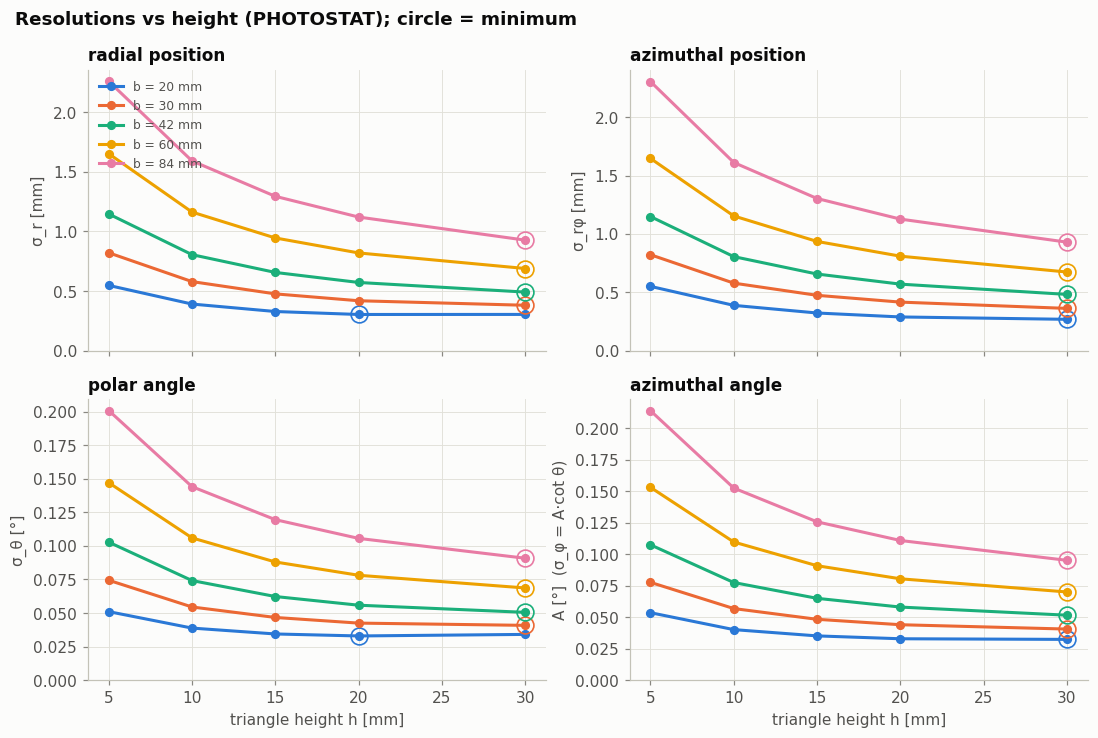

height [mm] giving the best value, per base [mm]


,radial position,azimuthal position,polar angle,azimuthal angle
base_mm,,,,
20.0,20.0,30.0,20.0,30.0
30.0,30.0,30.0,30.0,30.0
42.0,30.0,30.0,30.0,30.0
60.0,30.0,30.0,30.0,30.0
84.0,30.0,30.0,30.0,30.0


In [6]:
grid_plot(ph, "height_mm", "base_mm", "triangle height h [mm]",
          "Resolutions vs height (PHOTOSTAT); circle = minimum", lambda b: f"b = {b:.0f} mm", mark_min=True)
best_h = pd.DataFrame({name: ph.loc[ph.groupby("base_mm")[col].idxmin()].set_index("base_mm").height_mm
                       for col, lab, name in METRICS})
print("height [mm] giving the best value, per base [mm]")
best_h

The trade-off: taller bars deposit more energy (better photostatistics, σ_E/E ∝ 1/√h) but increase multiple scattering and δ-ray fluctuations; see the conclusions for where the optimum falls.

## 5. Resolution maps

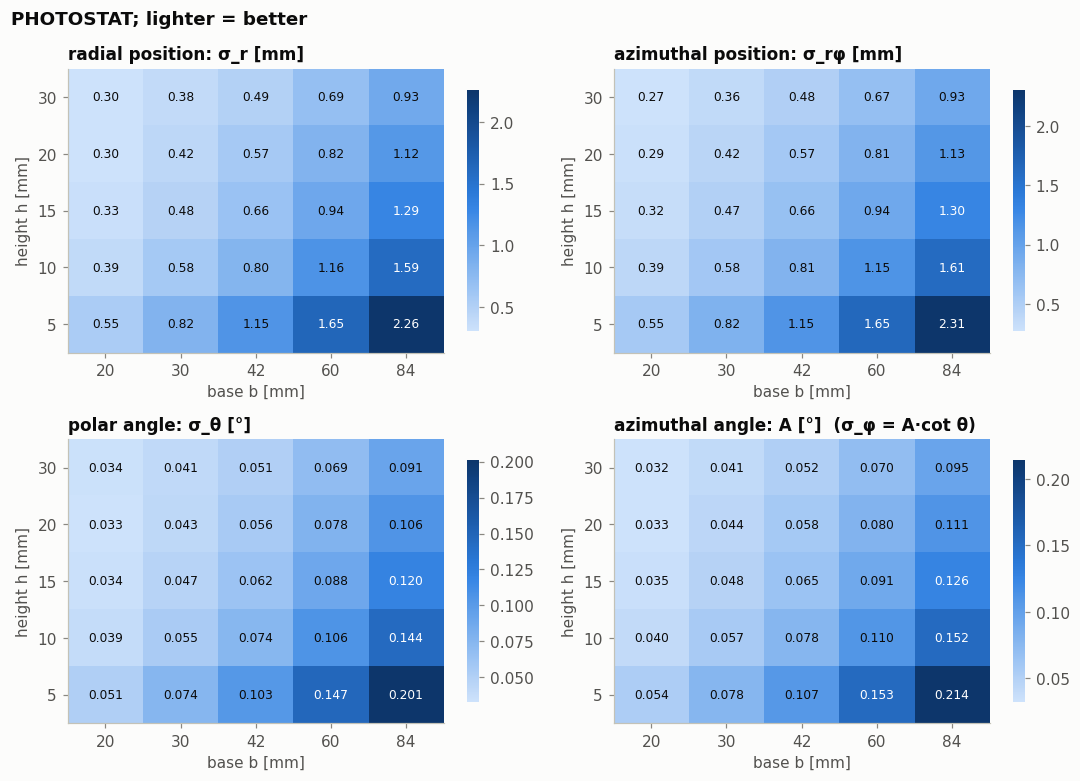

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(10, 7.2))
for ax, (col, lab, name) in zip(axs.flat, METRICS):
    M = ph.pivot(index="height_mm", columns="base_mm", values=col)
    im = ax.imshow(M.values, origin="lower", aspect="auto", cmap="sith_blue")
    ax.set_xticks(range(len(M.columns)), [f"{b:.0f}" for b in M.columns])
    ax.set_yticks(range(len(M.index)), [f"{h:.0f}" for h in M.index])
    ax.grid(False)
    vmax = np.nanmax(M.values)
    fmt = "{:.2f}" if "mm" in col else "{:.3f}"
    for (i, j), v in np.ndenumerate(M.values):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="#ffffff" if v > 0.55 * vmax else sp.INK)
    ax.set(xlabel="base b [mm]", ylabel="height h [mm]", title=f"{name}: {lab}")
    cb = fig.colorbar(im, ax=ax, shrink=0.85); cb.outline.set_visible(False)
fig.suptitle("PHOTOSTAT; lighter = better", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 6. The cost: position resolution versus number of channels

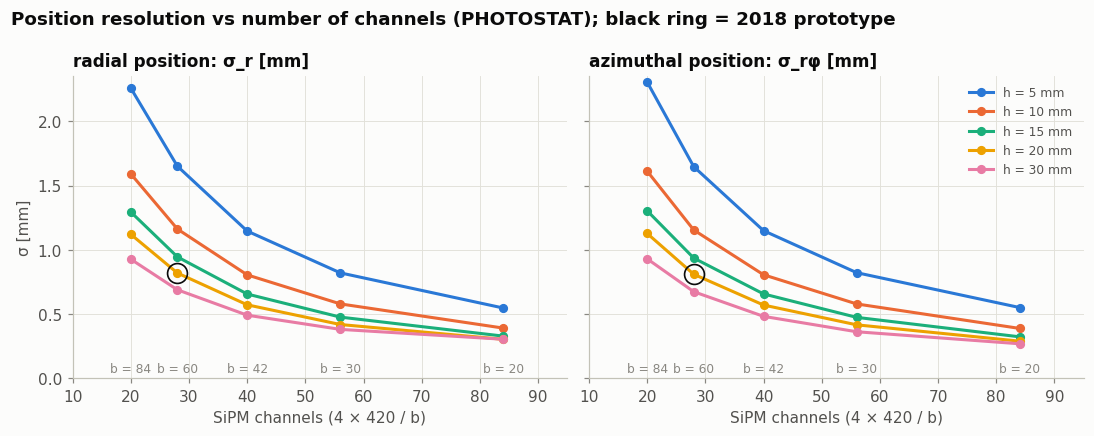

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (col, lab, name) in zip(axs, METRICS[:2]):
    for i, h in enumerate(HEIGHTS):
        g = ph[ph.height_mm == h].sort_values("channels")
        ax.plot(g.channels, g[col], "o-", color=sp.SERIES[i], ms=5, label=f"h = {h:.0f} mm")
    ax.plot(proto.channels, proto[col], "o", ms=13, mfc="none", mec=sp.INK, mew=1.1)
    for b in BASES:
        ax.annotate(f"b = {b:.0f}", (4 * 420 / b, 0), xytext=(0, 4), textcoords="offset points", ha="center", color=sp.MUTED, fontsize=8)
    ax.set(xlim=(10, 95), ylim=(0, None), xlabel="SiPM channels (4 × 420 / b)", title=f"{name}: {lab}")
axs[0].set_ylabel("σ [mm]"); axs[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Position resolution vs number of channels (PHOTOSTAT); black ring = 2018 prototype", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 7. Efficiency

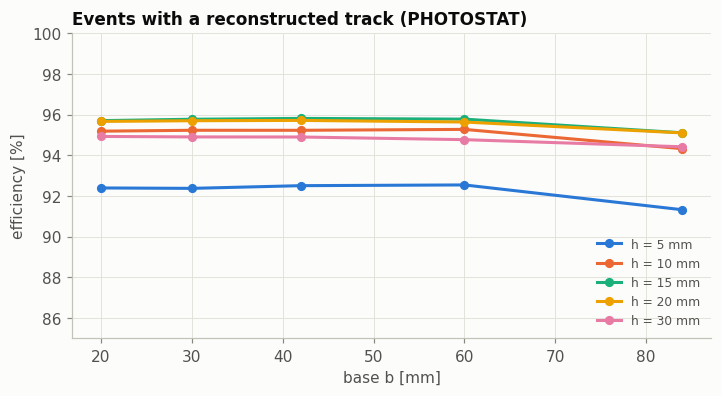

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, h in enumerate(HEIGHTS):
    g = ph[ph.height_mm == h].sort_values("base_mm")
    ax.plot(g.base_mm, 100 * g.efficiency, "o-", color=sp.SERIES[i], ms=5, label=f"h = {h:.0f} mm")
ax.set(xlabel="base b [mm]", ylabel="efficiency [%]", title="Events with a reconstructed track (PHOTOSTAT)", ylim=(85, 100))
ax.legend(loc="lower right", fontsize=8)
plt.show()

The efficiency (~95%) is limited mostly by the corners of the central hole at low theta (the same for all geometries) and drops by a few points for the thinnest bars, where more deposits near the apexes fall below the 35 keV threshold.

## 8. Residual distributions for three geometries

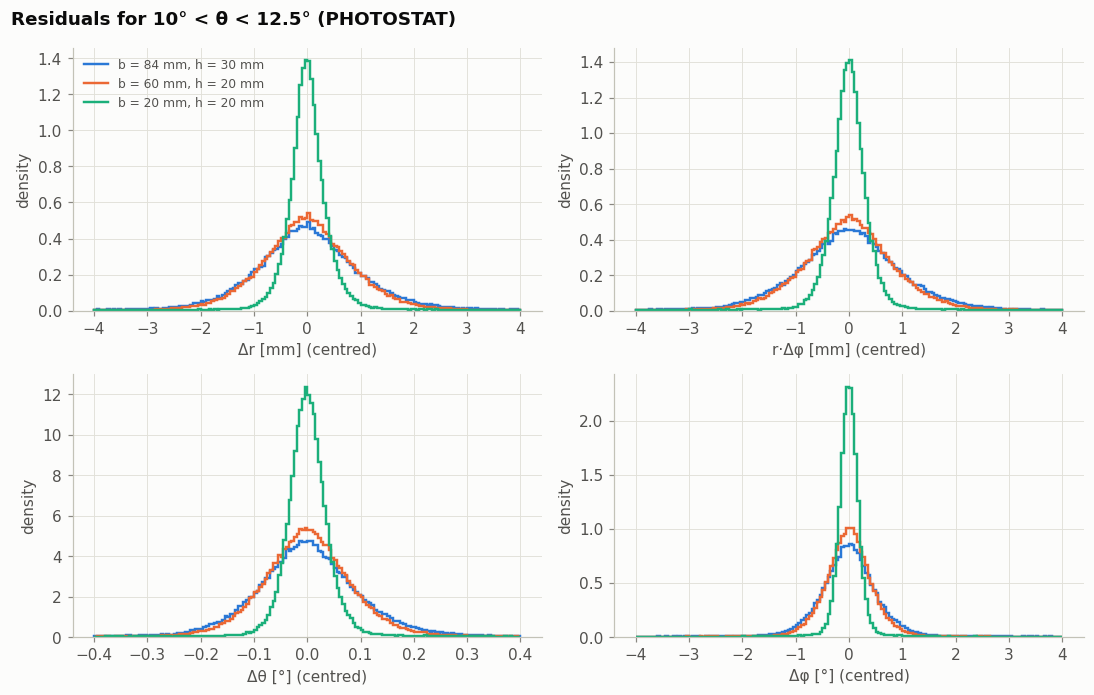

In [10]:
def residuals(b, h):
    d = R / "photostat" / f"b{b}_h{h}"
    geom = sr.Geometry.from_config(d / "config_last.cfg")
    F, B, gen = sr.load(sr.run_files(str(d / "output" / "*MeV_t*-{run}.root"), 0), geom,
                        extra=("theta_lab", "phi_lab", "position_X", "position_Y"))
    rec = sr.reconstruct(F, B, geom)
    t = np.tan(gen["theta_lab"])
    xt = gen["position_X"] / 10 + geom.dF * t * np.cos(gen["phi_lab"])
    yt = gen["position_Y"] / 10 + geom.dF * t * np.sin(gen["phi_lab"])
    rt, pt = np.hypot(xt, yt), np.arctan2(yt, xt)
    rr, pr = np.hypot(rec["xl"], rec["yl"]), np.arctan2(rec["yl"], rec["xl"])
    tg = np.degrees(gen["theta_lab"])
    m = (tg > 10) & (tg < 12.5) & np.isfinite(rec["theta"])
    wrap = lambda a, p: (a + p / 2) % p - p / 2
    return {"Δr [mm]": 10 * (rr - rt)[m], "r·Δφ [mm]": 10 * (rt * wrap(pr - pt, 2 * np.pi))[m],
            "Δθ [°]": (rec["theta"] - tg)[m], "Δφ [°]": wrap(rec["phi"] - np.degrees(gen["phi_lab"]), 360)[m]}

geoms = ((84, 30), (60, 20), (20, 20))
res = {g: residuals(*g) for g in geoms}
fig, axs = plt.subplots(2, 2, figsize=(10, 6.4))
ranges = {"Δr [mm]": 4, "r·Δφ [mm]": 4, "Δθ [°]": 0.4, "Δφ [°]": 4}
for ax, k in zip(axs.flat, ranges):
    for i, g in enumerate(geoms):
        v = res[g][k]
        sp.hist_line(ax, v - np.median(v), 160, (-ranges[k], ranges[k]), sp.SERIES[i], density=True,
                     label=f"b = {g[0]} mm, h = {g[1]} mm")
    ax.set(xlabel=k + " (centred)", ylabel="density")
axs[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Residuals for 10° < θ < 12.5° (PHOTOSTAT)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Conclusions and limitations

* **Position resolution is isotropic**: σ_r ≈ σ_rφ within a few % for every geometry (the two orthogonal layers have the same granularity). The angular resolutions follow from it, σ_θ ≈ σ_r / d and σ_φ ≈ σ_rφ / (d · tan θ), plus the beam-spot term.
* At fixed active area all four are dominated by the **base**: from 60 to 30 mm (h = 20) σ_r goes from 0.82 to 0.42 mm, σ_rφ from 0.81 to 0.42 mm, σ_θ from 0.078° to 0.043° and σ_φ from 0.081° to 0.044° · cot θ (×1.8–2.0), at the price of doubling the channels (28 → 56).
* The **height** matters through photostatistics: with respect to h = 20 mm, 5 mm bars are worse by a factor 1.8–2.0 in position and 1.5–1.9 in angle. From 20 to 30 mm the position still improves by 9–17% for b ≥ 30 mm, so the optimum is at or above 30 mm, outside the grid; for b = 20 mm 20 and 30 mm are equivalent (σ_r unchanged, σ_θ 4% worse, σ_rφ 7% better).
* Gains with respect to the prototype (position / angle): **b = 30, h = 30** ×2.2 / ×1.9–2.0 with 56 channels; **b = 42, h = 30** ×1.7 / ×1.55 with 40 channels; **b = 20, h = 20** ×2.7–2.8 / ×2.4 with 84 channels.
* The angles gain less than the positions because of the beam-spot term, which does not depend on the bars: for b = 20, h = 20 it is about a fifth of the σ_θ² budget. With a larger beam or target spot at COSY the angular gains shrink further, so the position resolution is the cleaner figure of merit for the tracker itself.
* To find how far it pays to make the bars taller, the grid should be extended to h = 40–50 mm for b ≥ 30 mm, taking into account the material in front of the LYSO (point 4 below).

**Limitations to keep in mind before drawing design conclusions:**

1. Same light yield per MeV for all geometries, and a smearing that scales as photostatistics. Notebook 04 simulates the light collection of each bar and repeats the scan with smearing models that scale differently with the deposited energy (CONSTANT, NOISE, OPTICAL): the energy dependence of the smearing turns out to matter more than the light collection.
2. The smearing calibration uses a single point (prototype geometry, 2018 test beam).
3. The reconstruction uses the nominal pitch b instead of b + 2·(aluminium thickness): 0.1–0.4% scale bias (absorbed by the per-bin fits, it does not affect σ).
4. Only 270 MeV deuterons without target: no background from inelastic scattering. Taller bars mean more plastic in front of the calorimeter (energy loss, nuclear interactions, worse LYSO energy resolution): this cost is not in the metric and limits the useful height.
5. The angles include the beam-spot term (σ = 0.15 / 0.20 mm, i.e. ≈ 0.014–0.019° at the front layer); with a larger beam or target spot at COSY this term grows, the position resolutions do not change.